# Manchas solares anuais — autorregressão

Dataset histórico de 309 observações (1700–2008), distribuído pelo statsmodels.
[Fonte e descrição](https://www.statsmodels.org/stable/datasets/generated/sunspots.html).
Vamos prever o próximo ano usando apenas valores reais de anos anteriores.
Há treino, validação para escolher p e teste reservado para a avaliação final.
Rode este notebook na pasta do projeto, no ambiente uv.


In [1]:
from pathlib import Path
from IPython.display import display, Image
from manchas_solares import executar, exportar, gerar_graficos

pasta = Path.cwd()
experimento = executar(pasta)
display(experimento['configuracao'])


,Item,Valor
0,Dataset,"Sunspots anual, 309 observações de 1700 a 2008"
1,Fonte,https://raw.githubusercontent.com/statsmodels/...
2,Documentação,https://www.statsmodels.org/stable/datasets/ge...
3,SHA256,f67889b1d9002cd5227f0e0ef54e35b419cdd85a31279a...
4,Treino inicial,1700–1884 (185 anos)
5,Validação,1885–1946 (62 anos)
6,Teste final,1947–2008 (62 anos)
7,Modelo,"AR(19), com intercepto, sem variáveis externas"
8,Seleção de p,Menor MAE na validação entre p=1 e p=30; desem...
9,Hold-back na seleção,30 observações em todos os candidatos


## Escolha da ordem do modelo

Testamos p=1 a 30 somente na validação e escolhemos o menor MAE.
Todos os candidatos usam o mesmo hold-back inicial de 30 anos.
Depois ajustamos o modelo escolhido com treino + validação, com hold-back=p.
Não usamos o teste para escolher a ordem ou reajustar coeficientes.


In [2]:
print(f"Modelo selecionado: AR({experimento['p']})")
display(experimento['selecao'].round(3))
metricas = experimento['metricas'].copy()
metricas['MAPE (%)'] *= 100
display(metricas.round(3))


Modelo selecionado: AR(19)


,Defasagens (p),MAE validação,RMSE validação
0,19,9.366,12.848
1,18,9.372,12.854
2,10,9.383,12.427
3,15,9.399,12.808
4,9,9.399,12.444
5,16,9.411,12.778
6,20,9.493,12.890
7,11,9.550,12.643
8,8,9.595,12.599
9,29,9.634,12.979


,Modelo,Anos avaliados,MAE,RMSE,R²,MAPE (%),MASE
0,Autorregressivo,62,15.278,20.241,0.853,36.267,0.933
1,Persistência,62,25.444,33.276,0.603,55.417,1.554


## Previsões de um passo à frente

Para prever o ano t, o modelo usa os valores reais de t−1, ..., t−p.
Depois de produzir a previsão, o real de t entra no histórico para prever t+1.
O modelo não usa seus próprios valores previstos como entrada neste protocolo.
Atividade negativa prevista é limitada a zero. A referência de persistência
repete o último real. O erro percentual fica vazio com real zero e pode ser
alto quando o real é pequeno. Compare também MAE, RMSE e MASE.


,Ano de origem,Ano previsto,Valor real,Valor predito,Erro absoluto,Taxa de erro (%),Persistência
0,1946,1947,151.6,120.243,31.357,20.684,92.6
1,1947,1948,136.3,159.760,23.460,17.212,151.6
2,1948,1949,134.7,103.958,30.742,22.822,136.3
3,1949,1950,83.9,104.354,20.454,24.379,134.7
4,1950,1951,69.4,47.835,21.565,31.074,83.9
...,...,...,...,...,...,...,...
57,2003,2004,40.4,26.561,13.839,34.256,63.7
58,2004,2005,29.8,25.207,4.593,15.413,40.4
59,2005,2006,15.2,25.363,10.163,66.863,29.8
60,2006,2007,7.5,5.279,2.221,29.609,15.2


Excel: /Users/ryanbernardo/Documents/Faculdade/MachineLearning/projeto_auto_regressao/resultados_manchas_solares/previsao_manchas_solares.xlsx


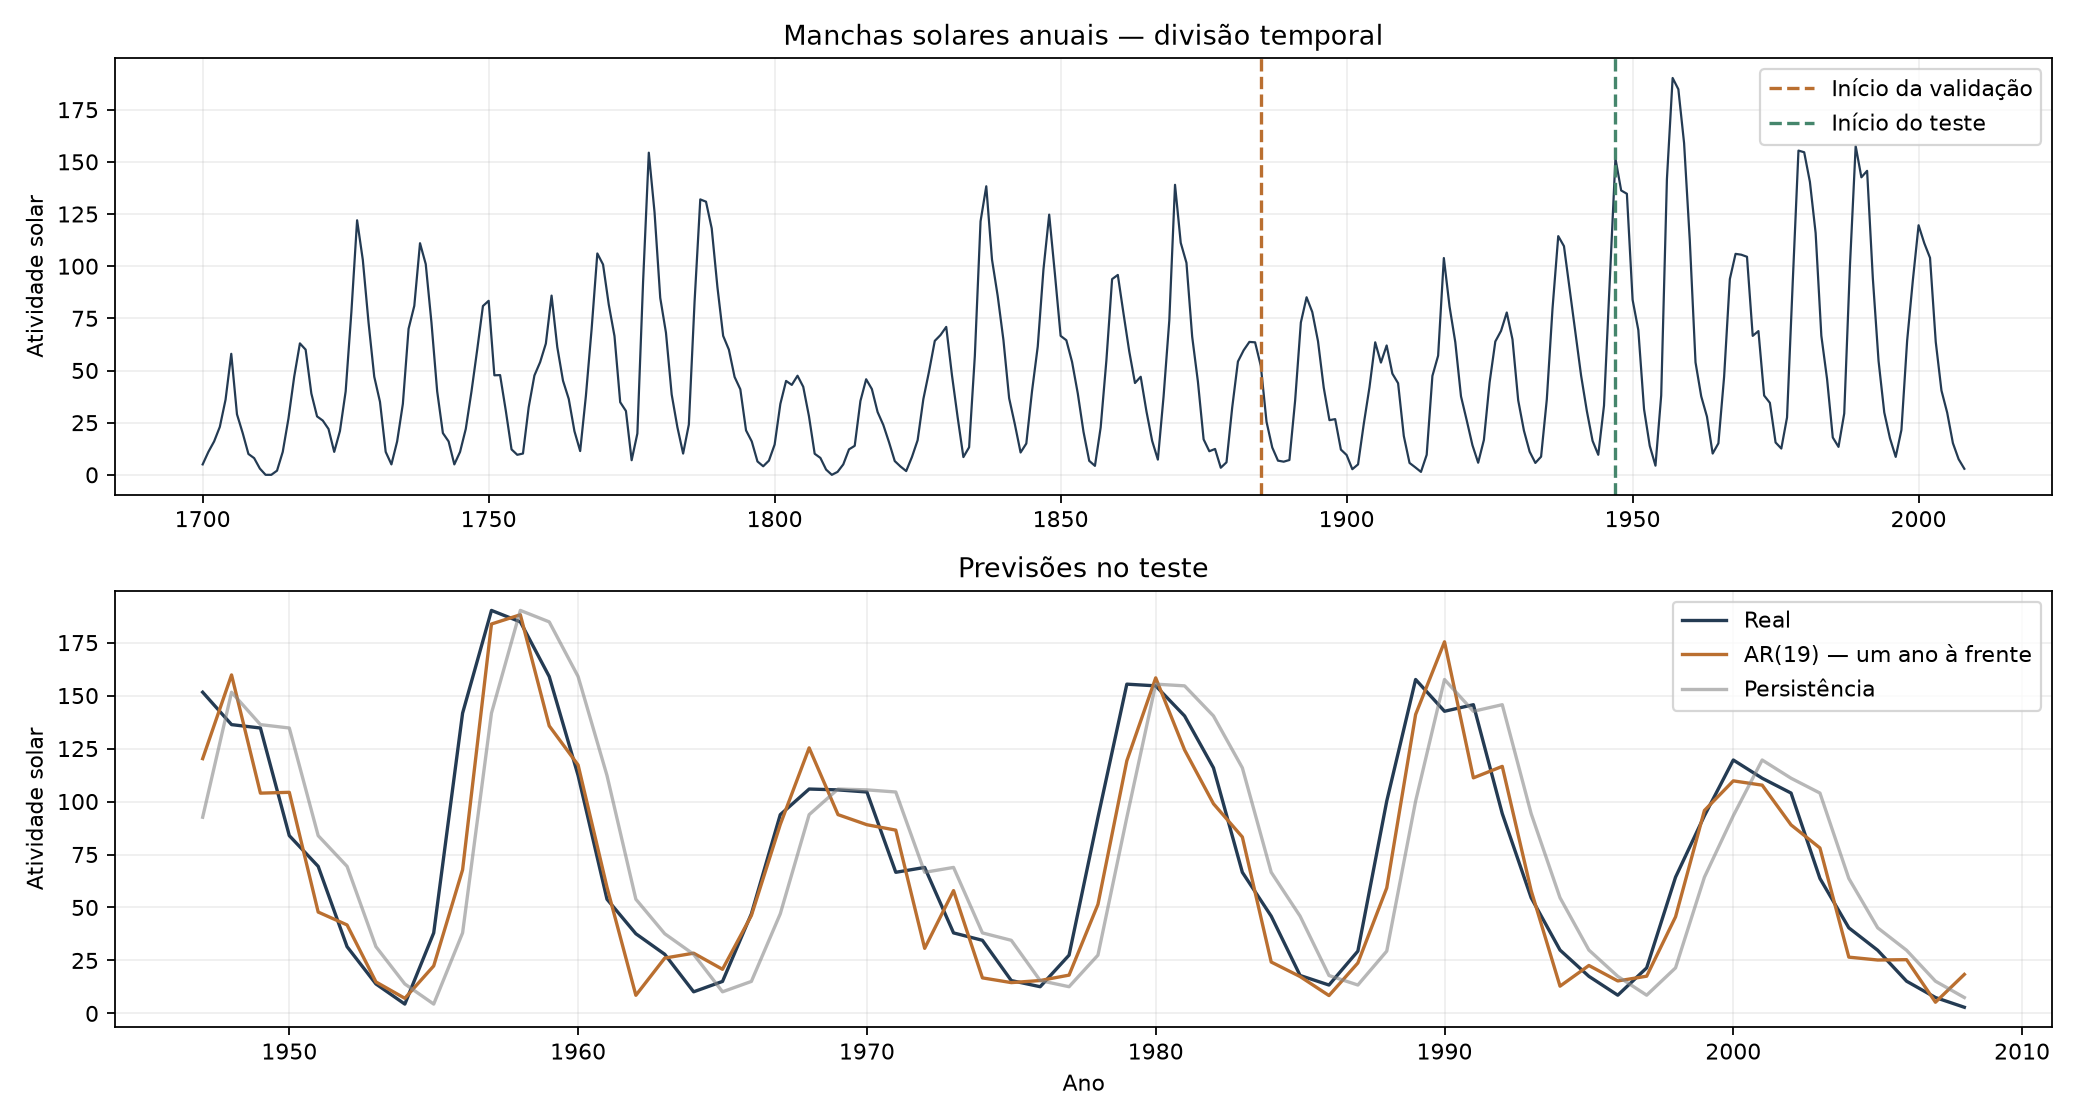

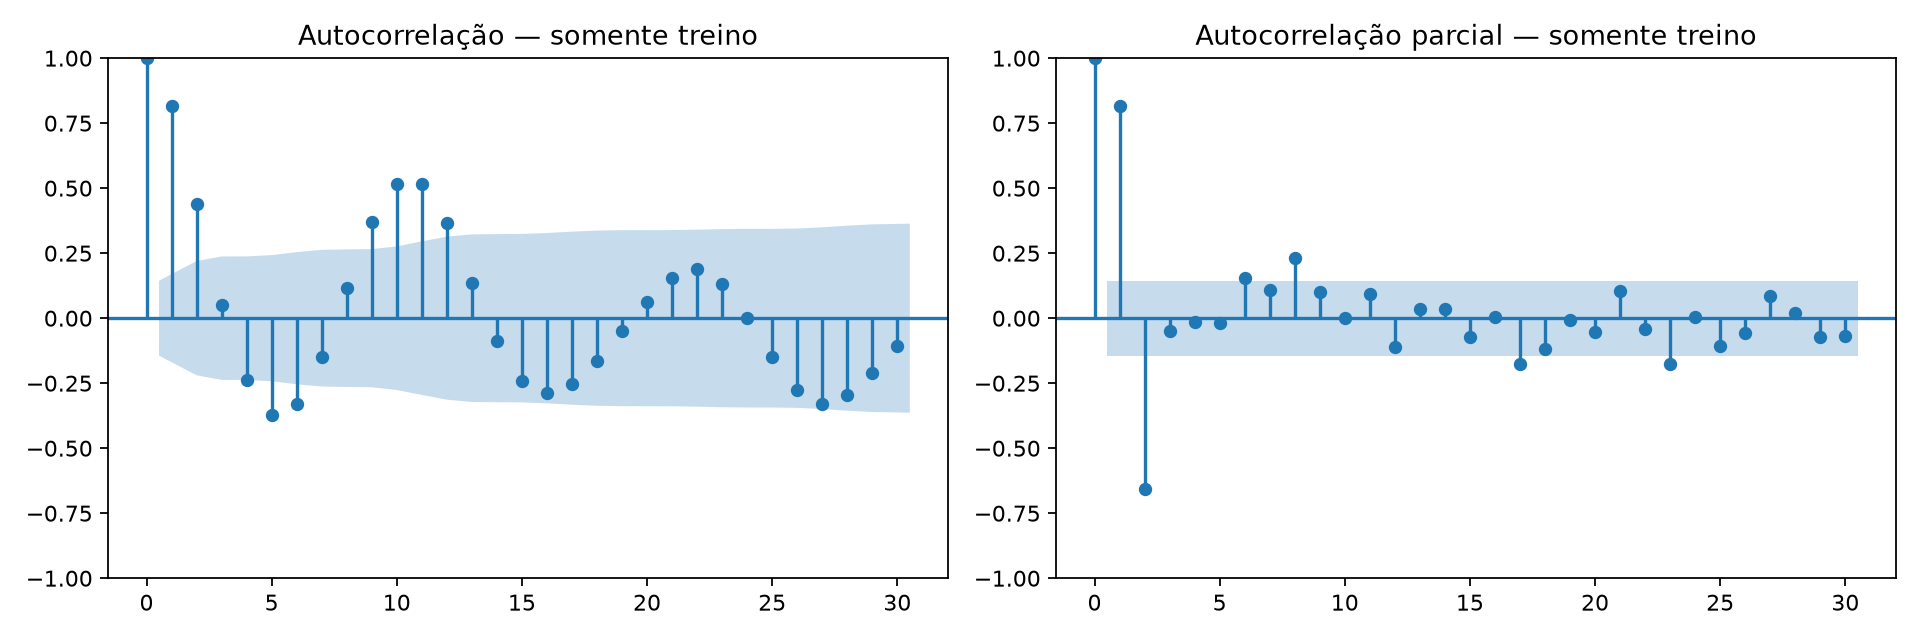

In [3]:
previsoes = experimento['teste'].copy()
previsoes['Taxa de erro (%)'] *= 100
display(previsoes.round(3))
saida = exportar(experimento, pasta)
gerar_graficos(experimento, pasta)
print('Excel:', saida)
display(Image(filename=str(saida.parent / 'previsoes.png')))
display(Image(filename=str(saida.parent / 'autocorrelacao.png')))
